
1. **Data Extraction**
   - Extracts the raw dataset (`Dataset.zip`) into the `raw_data` directory and lists all extracted folders and CSV files.

In [ ]:
unzip ("Dataset.zip", exdir = "raw_data")
list.files("raw_data", recursive =TRUE)

[1] "304/25429-1.CSV"   "304/25429-2.CSV"   "304/261103-1.CSV" 
 [4] "304/261103-17.CSV" "304/261103-18.CSV" "304/261103-4.CSV" 
 [7] "304/261103-5.CSV"  "304/261103-6.CSV"  "304/26717-2.CSV"  
[10] "304/26891-1.CSV"   "304/26891-2.CSV"   "304L/26723-1.CSV" 
[13] "304L/26723-2.CSV"  "304L/26723-3.CSV"  "304L/26723-4.CSV" 
[16] "304L/26723-5.CSV"  "304L/26723-6.CSV"  "304L/26723-7.CSV" 
[19] "304L/26723-8.CSV"  "316/25008-1.CSV"   "316/25008-2.CSV"  
[22] "316/25771-1.CSV"   "316/25771-2.CSV"   "316/25771-3.CSV"  
[25] "316/25771-4.CSV"   "316/25771-5.CSV"   "316/25922-1.CSV"  
[28] "316/25922-2.CSV"   "316/25922-3.CSV"   "316/25922-4.CSV"  
[31] "316L/25131-1.CSV"  "316L/25131-2.CSV"  "316L/25131-3.CSV" 
[34] "316L/261444-1.CSV" "316L/261453-1.CSV" "316L/261453-2.CSV"
[37] "316L/26320-1.CSV"  "316L/26320-5.CSV"  "316L/26363-1.CSV" 
[40] "316L/26363-2.CSV"

2. **Data Cleaning & Preprocessing**
   - Parses raw OES files to extract specific steel elements (`C`, `Si`, `Mn`, `Cr`, `Mo`, `Ni`).
   - Splits the data into training and test sets.
   - Balances the training data across different steel grades to avoid class imbalance and saves the cleaned datasets as CSVs.

In [ ]:
clean_single_oes <- function(filepath, grade_label) {
  lines <- readLines(filepath, warn = FALSE)
  header_idx <- grep("^,Fe", lines)[1]
  if (is.na(header_idx)) return(NULL) # ignore if error

  col_names <- trimws(unlist(strsplit(lines[header_idx], ",")))
  col_names[1] <- "shot"

  raw_df <- read.csv(text = lines[(header_idx + 3):length(lines)], header = FALSE)
  colnames(raw_df) <- col_names[1:ncol(raw_df)]

  clean_df <- raw_df[grepl("^[0-9]+$", trimws(raw_df$shot)), ]
  clean_df$shot <- as.integer(trimws(clean_df$shot))

  elements <- c("C", "Si", "Mn", "Cr", "Mo", "Ni")
  for (el in elements) {
    val_str <- trimws(as.character(clean_df[[el]]))
    is_lod  <- grepl("\\[<\\]", val_str)
    num_val <- as.numeric(gsub("\\[<\\]", "", val_str))
    num_val[is_lod] <- num_val[is_lod] / 2
    clean_df[[el]] <- num_val
  }

  clean_df$grade <- paste0("SS", grade_label)
  clean_df$block <- tools::file_path_sans_ext(basename(filepath))

  return(clean_df[, c("grade", "block", "shot", elements)])
}

grades <- c("304", "304L", "316", "316L")
base_dir <- "/content/raw_data"

train_list <- list()
test_list  <- list()

for (g in grades) {
  folder_path <- file.path(base_dir, g)
  csv_files <- sort(list.files(folder_path, pattern = "\\.CSV$", full.names = TRUE, ignore.case = TRUE))

  test_file_path  <- tail(csv_files, 1)
  train_file_paths <- head(csv_files, -1)

  cat(sprintf("Grade SS%-4s | Total file: %2d | File remain for Testing: %s\n",
              g, length(csv_files), basename(test_file_path)))

  test_list[[g]] <- clean_single_oes(test_file_path, g)

  grade_train_dfs <- lapply(train_file_paths, clean_single_oes, grade_label = g)
  train_list[[g]] <- do.call(rbind, grade_train_dfs)
}

full_train_df <- do.call(rbind, train_list)
test_df       <- do.call(rbind, test_list)
rownames(full_train_df) <- NULL
rownames(test_df)       <- NULL

cat("\n Shot before balance: \n")
print(table(full_train_df$grade))

set.seed(42)
min_n <- min(table(full_train_df$grade))

balanced_train_df <- do.call(rbind, lapply(split(full_train_df, full_train_df$grade), function(sub_df) {
  sub_df[sample(nrow(sub_df), min_n), ]
}))
rownames(balanced_train_df) <- NULL

cat("\nShot after balance:\n")
print(table(balanced_train_df$grade))

write.csv(balanced_train_df, "oes_train_balanced.csv", row.names = FALSE)
write.csv(full_train_df,     "oes_train_full.csv",     row.names = FALSE)
write.csv(test_df,           "oes_test_holdout.csv",   row.names = FALSE)
cat("\nPlease don't error!\n")

Grade SS304  | Total file: 11 | File remain for Testing: 26891-2.CSV
Grade SS304L | Total file:  8 | File remain for Testing: 26723-8.CSV
Grade SS316  | Total file: 11 | File remain for Testing: 25922-4.CSV
Grade SS316L | Total file: 10 | File remain for Testing: 26363-2.CSV

 Shot before balance: 

 SS304 SS304L  SS316 SS316L 
    27     17     33     34 

Shot after balance:

 SS304 SS304L  SS316 SS316L 
    17     17     17     17 

Please don't error!



3. **Univariate Normality Test**
   - Conducts the Shapiro-Wilk test on each chemical element within each steel grade using the full training set to check for univariate normality.

In [ ]:
# Shapiro-Wilk W and p-value table for report
train <- read.csv("oes_train_full.csv")
elements <- c("C", "Si", "Mn", "Cr", "Mo", "Ni")

fmt_cell <- function(x) {
  x <- x[is.finite(x)]
  res <- shapiro.test(x)
  w_str <- sprintf("%.4f", unname(res$statistic))
  p_str <- if (res$p.value < 0.001) {
    sprintf("%.2e", res$p.value)
  } else {
    sprintf("%.3f", res$p.value)
  }
  paste0(w_str, " (", p_str, ")")
}

report_mat <- sapply(elements, function(el) {
  tapply(train[[el]], train$grade, fmt_cell)
})

n_vec <- tapply(train$C, train$grade, function(x) sum(is.finite(x)))
report_df <- data.frame(
  Grade = names(n_vec),
  n = as.integer(n_vec),
  report_mat,
  row.names = NULL,
  check.names = FALSE
)

print(report_df, row.names = FALSE)

  Grade  n              C             Si                Mn             Cr
  SS304 27 0.9388 (0.114) 0.9428 (0.143) 0.8354 (6.00e-04) 0.9394 (0.118)
 SS304L 17 0.9555 (0.548) 0.9683 (0.788)    0.9686 (0.794) 0.9440 (0.368)
  SS316 33 0.9403 (0.069) 0.9025 (0.006)    0.8952 (0.004) 0.9385 (0.061)
 SS316L 34 0.9832 (0.868) 0.9147 (0.011) 0.7168 (9.01e-07) 0.9257 (0.023)
                Mo                Ni
 0.6467 (7.63e-07) 0.7171 (6.78e-06)
    0.9015 (0.072)    0.9141 (0.117)
    0.9324 (0.041)    0.9782 (0.731)
    0.9468 (0.098) 0.8285 (9.57e-05)


4. **Multivariate Normality Test**
   - Performs Mardia's test of multivariate skewness and kurtosis for each steel grade to verify if the chemical elements follow a multivariate normal distribution.

In [ ]:
mardia <- function(x) {
  x <- as.matrix(x); n <- nrow(x); p <- ncol(x)
  xc <- scale(x, center = TRUE, scale = FALSE)
  S <- crossprod(xc) / n # ML covariance
  D <- xc %*% solve(S) %*% t(xc)
  b1 <- mean(D^3) # multivariate skewness
  b2 <- mean(diag(D)^2) # multivariate kurtosis
  skew_stat <- n * b1 / 6
  skew_df <- p * (p + 1) * (p + 2) / 6
  kurt_z <- (b2 - p * (p + 2)) / sqrt(8 * p * (p + 2) / n)
  c(n = n, skew_stat = skew_stat,
    skew_p = pchisq(skew_stat, skew_df, lower.tail = FALSE),
    kurt_z = kurt_z, kurt_p = 2 * pnorm(-abs(kurt_z)))
}

train <- read.csv("oes_train_full.csv")
train$grade <- factor(train$grade)
elements <- c("C", "Si", "Mn", "Cr", "Mo", "Ni")

mardia_results <- t(sapply(levels(train$grade),
                         function(g) mardia(train[train$grade == g, elements])))
print(round(mardia_results, 4))

        n skew_stat skew_p  kurt_z kurt_p
SS304  27   97.8912 0.0005  0.3415 0.7327
SS304L 17   32.7254 0.9945 -1.5572 0.1194
SS316  33   65.0778 0.1901 -2.4191 0.0156
SS316L 34  104.9363 0.0001 -0.4394 0.6603


5. **Homogeneity of Variances Test**
   - Installs the `biotools` library and applies Bartlett's test to determine if the variances of individual elements are equal across different steel grades.

In [ ]:
library(biotools)
library(broom)

train <- read.csv("oes_train_full.csv")
elements <- c("C", "Si", "Mn", "Cr", "Mo", "Ni")

box_m <- tidy(boxM(train[elements], train$grade))
box_out <- data.frame(
  Test = "Box's M",
  df = box_m$parameter,
  Chi_sq = round(box_m$statistic, 2),
  p_value = formatC(box_m$p.value, format = "e", digits = 2),
  sig_0.05 = ifelse(box_m$p.value < 0.05, "Yes", "No")
)

bartlett_out <- do.call(rbind, lapply(elements, function(el) {
  bt <- tidy(bartlett.test(train[[el]] ~ train$grade))
  data.frame(
    Element = el,
    df = bt$parameter,
    K_sq = round(bt$statistic, 2),
    p_value = ifelse(bt$p.value < 0.001,
                     formatC(bt$p.value, format = "e", digits = 2),
                     sprintf("%.4f", bt$p.value)),
    sig_0.05 = ifelse(bt$p.value < 0.05, "Yes", "No")
  )
}))

print(box_out, row.names = FALSE)
cat("\n")
print(bartlett_out, row.names = FALSE)

    Test df Chi_sq  p_value sig_0.05
 Box's M 63 249.33 5.39e-24      Yes

 Element df  K_sq  p_value sig_0.05
       C  3 34.09 1.90e-07      Yes
      Si  3  8.30   0.0403      Yes
      Mn  3 15.72   0.0013      Yes
      Cr  3  4.64   0.1999       No
      Mo  3 13.10   0.0044      Yes
      Ni  3 10.46   0.0150      Yes


6. **Classification on Balanced Data and Full Data**
   - Builds Linear Discriminant Analysis (LDA) and Quadratic Discriminant Analysis (QDA) classifiers on the balanced dataset.
   - Evaluates performance using Leave-One-Out Cross-Validation (LOOCV) and a holdout test set.

In [ ]:
library(MASS)

# Generic helper function to run any classifier model (LDA/QDA) on any dataset
evaluate_classifier <- function(train_path, test_path = "oes_test_holdout.csv", method_func, method_name, dataset_label) {
  cat(sprintf("=== %s MODEL ON: %s ===\n", toupper(method_name), toupper(dataset_label)))

  # Read datasets
  train <- read.csv(train_path)
  test  <- read.csv(test_path)
  train$grade <- factor(train$grade)
  test$grade  <- factor(test$grade)

  # 1. Train the model
  fit <- method_func(grade ~ C + Si + Mn + Cr + Mo + Ni, data = train)
  if (method_name == "LDA") {
    print(fit) # Only print coefficients detail for LDA
  }

  # 2. Evaluate LOOCV (Leave-One-Out Cross-Validation)
  cv <- method_func(grade ~ C + Si + Mn + Cr + Mo + Ni, data = train, CV = TRUE)
  conf_cv <- table(Truth = train$grade, Predicted = cv$class)
  cat(sprintf("\n%s LOOCV Confusion Matrix:\n", method_name))
  print(conf_cv)
  cat(sprintf("%s LOOCV Accuracy: %.2f%%\n\n", method_name, sum(diag(conf_cv)) / sum(conf_cv) * 100))

  # 3. Evaluate on the independent holdout test set
  pred_test <- predict(fit, newdata = test)
  conf_test <- table(Truth = test$grade, Predicted = pred_test$class)
  cat(sprintf("%s Test Confusion Matrix:\n", method_name))
  print(conf_test)
  cat(sprintf("%s Test Accuracy: %.2f%%\n\n", method_name, sum(diag(conf_test)) / sum(conf_test) * 100))

  return(fit)
}

# --- 1. EVALUATE ON BALANCED DATASET ---
lda_balanced <- evaluate_classifier("oes_train_balanced.csv", "oes_test_holdout.csv", lda, "LDA", "Balanced Dataset")
qda_balanced <- evaluate_classifier("oes_train_balanced.csv", "oes_test_holdout.csv", qda, "QDA", "Balanced Dataset")

# --- 2. EVALUATE ON FULL UNBALANCED DATASET ---
lda_full <- evaluate_classifier("oes_train_full.csv", "oes_test_holdout.csv", lda, "LDA", "Full Dataset")
qda_full <- evaluate_classifier("oes_train_full.csv", "oes_test_holdout.csv", qda, "QDA", "Full Dataset")

=== LDA MODEL ON: BALANCED DATASET ===
Call:
lda(grade ~ C + Si + Mn + Cr + Mo + Ni, data = train)

Prior probabilities of groups:
 SS304 SS304L  SS316 SS316L 
  0.25   0.25   0.25   0.25 

Group means:
                C        Si       Mn       Cr         Mo        Ni
SS304  0.05967647 0.3135824 1.070335 19.00059 0.06618353  8.563235
SS304L 0.02349824 0.1948941 1.771588 19.20588 0.11101765  8.518000
SS316  0.03637647 0.3980882 1.318112 17.74765 2.11141176 10.332882
SS316L 0.02575882 0.5372941 1.163682 17.51588 2.08735294 10.354412

Coefficients of linear discriminants:
           LD1        LD2         LD3
C   17.1181292 73.6947973  52.9031679
Si   0.6938352  0.7295772 -12.2964549
Mn   1.0759196 -3.1774715   0.5992479
Cr  -0.4723360 -0.4460865   0.2493187
Mo -14.2298638  0.2495456   1.3181904
Ni  -0.7468540 -0.5855721   0.5530772

Proportion of trace:
   LD1    LD2    LD3 
0.9823 0.0143 0.0034 

LDA LOOCV Confusion Matrix:
        Predicted
Truth    SS304 SS304L SS316 SS316L
  SS304  

8. **LDA Projection Plot**
   - Visualizes the classification using a 2D scatter plot of the first two linear discriminants (LD1 vs. LD2) with 95% confidence ellipses for each steel grade.

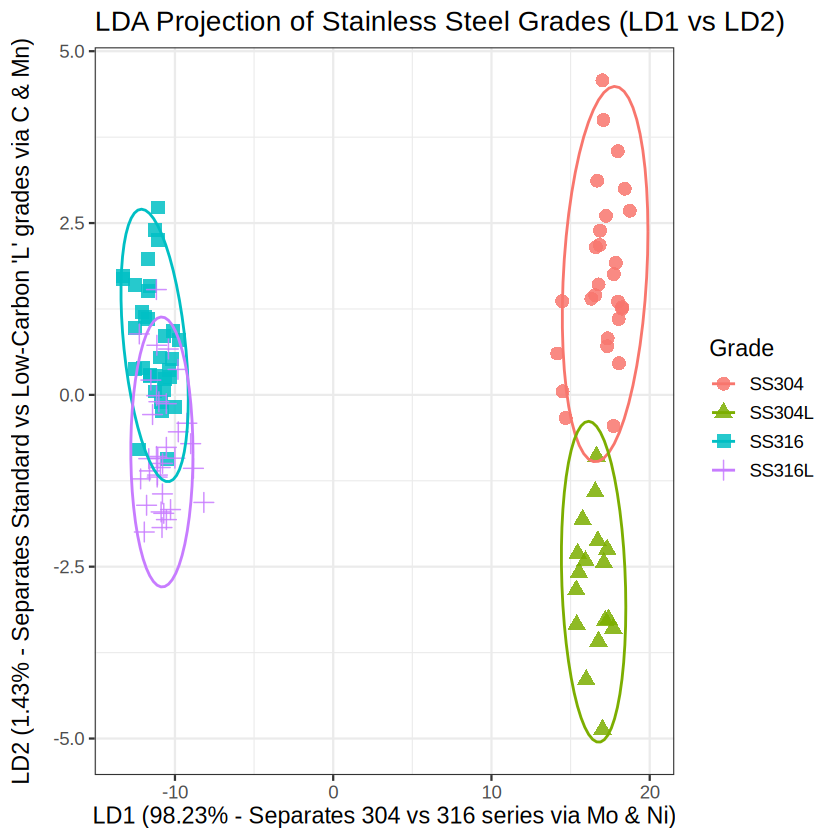

In [ ]:
library(ggplot2)
lda_scores <- as.data.frame(predict(lda_model)$x)
lda_scores$Grade <- train$grade
p <- ggplot(lda_scores, aes(x = LD1, y = LD2, color = Grade, shape = Grade)) +
  geom_point(size = 3.5, alpha = 0.85) +
  stat_ellipse(level = 0.95, linewidth = 0.8) +
  theme_bw(base_size = 14) +
  labs(
    title = "LDA Projection of Stainless Steel Grades (LD1 vs LD2)",
    x = "LD1 (98.23% - Separates 304 vs 316 series via Mo & Ni)",
    y = "LD2 (1.43% - Separates Standard vs Low-Carbon 'L' grades via C & Mn)"
  )
print(p)
ggsave("lda_slide_plot.png", plot = p, width = 8, height = 5.5, dpi = 300)


9. **QDA Decision Boundaries**
   - Installs `klaR` and plots the non-linear decision boundaries of the QDA model using Carbon (C) and Molybdenum (Mo) as dimensions.

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



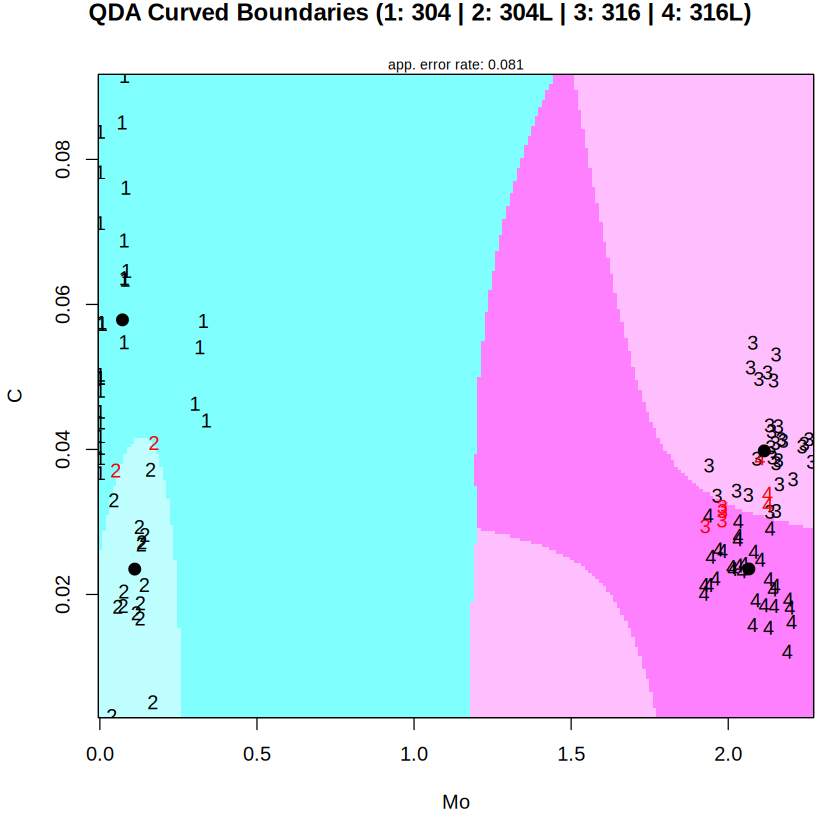

In [ ]:
install.packages("klaR")
library(klaR)

partimat(grade ~ C + Mo, data = train, method = "qda",
         prec = 200,
         gs = as.character(as.numeric(train$grade)),
         main = "QDA Curved Boundaries (1: 304 | 2: 304L | 3: 316 | 4: 316L)")

10. **Feature Importance Comparison**
    - Trains models with and without Carbon (C) to demonstrate how critical Carbon concentration is to successfully distinguishing standard grades from low-carbon 'L' grades.

In [ ]:
lda_no_C <- lda(grade ~ Si + Mn + Cr + Mo + Ni, data = train, CV = TRUE)
qda_no_C <- qda(grade ~ Si + Mn + Cr + Mo + Ni, data = train, CV = TRUE)

acc_lda_no_C <- sum(diag(table(train$grade, lda_no_C$class))) / nrow(train)
acc_qda_no_C <- sum(diag(table(train$grade, qda_no_C$class))) / nrow(train)

cat("\n Compare LDA and QDA LOOCV with 'C' and No 'C'\n")
cat(sprintf("LDA Accuracy: With C = %5.2f%%  --->  No C = %5.2f%%\n", lda_accuracy * 100, acc_lda_no_C * 100))
cat(sprintf("QDA Accuracy: With C = %5.2f%%  --->  No C = %5.2f%%\n", qda_accuracy * 100, acc_qda_no_C * 100))
cat("\nConfusion Matrix of LDA with no C:\n")
print(table(Truth = train$grade, Predicted = lda_no_C$class))

cat("\nConfusion Matrix of QDA with no C:\n")
print(table(Truth = train$grade, Predicted = qda_no_C$class))


 Compare LDA and QDA LOOCV with 'C' and No 'C'
LDA Accuracy: With C = 93.69%  --->  No C = 83.78%
QDA Accuracy: With C = 96.40%  --->  No C = 84.68%

Confusion Matrix of LDA with no C:
        Predicted
Truth    SS304 SS304L SS316 SS316L
  SS304     25      2     0      0
  SS304L     0     17     0      0
  SS316      0      0    27      6
  SS316L     0      0    10     24

Confusion Matrix of QDA with no C:
        Predicted
Truth    SS304 SS304L SS316 SS316L
  SS304     27      0     0      0
  SS304L     0     17     0      0
  SS316      0      0    26      7
  SS316L     0      0    10     24


11. **Element Contribution to Group Separation**
    - Multiplies each LDA coefficient by the gap between two group means, so the result does not depend on measurement units.
    - Shows how much each element adds to the LD1 gap (304 vs 316 family) and the LD2 gaps (standard vs L grade).

In [ ]:
# Contribution of each element = LDA coefficient x gap between group means.
# LDA coefficients already account for within-grade variation, so this shows
# how much of the separation each element supplies, whatever its scale.
m <- lda_model$means      # group means (rows: grades, columns: elements)
b <- lda_model$scaling    # LDA coefficients (rows: elements, columns: LD1-LD3)

contrib <- function(axis, from, to, label) {
  gap <- colMeans(m[to, , drop = FALSE]) - colMeans(m[from, , drop = FALSE])
  gap <- gap[rownames(b)]                       # same element order as b
  x   <- b[, axis] * gap
  cat("\n", label, " (", axis, " gap = ", round(sum(x), 2), ")\n", sep = "")
  print(data.frame(Element      = names(x),
                   Contribution = round(x, 2),
                   Share_pct    = round(100 * x / sum(x), 1)),
        row.names = FALSE)
}

contrib("LD1", c("SS304", "SS304L"), c("SS316", "SS316L"), "316 family vs 304 family")
contrib("LD2", "SS304", "SS304L", "SS304L vs SS304")
contrib("LD2", "SS316", "SS316L", "SS316L vs SS316")


316 family vs 304 family (LD1 gap = -27.78)
 Element Contribution Share_pct
       C        -0.09       0.3
      Si         0.63      -2.3
      Mn        -0.21       0.7
      Cr         0.72      -2.6
      Mo       -26.98      97.1
      Ni        -1.86       6.7

SS304L vs SS304 (LD2 gap = -4.49)
 Element Contribution Share_pct
       C        -2.93      65.2
      Si         0.15      -3.4
      Mn        -1.70      37.8
      Cr        -0.01       0.3
      Mo         0.03      -0.7
      Ni        -0.03       0.8

SS316L vs SS316 (LD2 gap = -1.53)
 Element Contribution Share_pct
       C        -1.39      90.4
      Si        -0.12       7.8
      Mn         0.08      -5.4
      Cr         0.03      -2.1
      Mo        -0.04       2.5
      Ni        -0.11       6.9
